## Mini Project 1 - Phân tích hóa đơn ngày Thứ Bảy

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### 1: Lọc các hóa đơn vào ngày Thứ Bảy

In [2]:
df_sat = df[df['day'] == 'Sat']
df_sat.head()

,total_bill,tip,sex,smoker,day,time,size
19,20.65,3.35,Male,No,Sat,Dinner,3
20,17.92,4.08,Male,No,Sat,Dinner,2
21,20.29,2.75,Female,No,Sat,Dinner,2
22,15.77,2.23,Female,No,Sat,Dinner,2
23,39.42,7.58,Male,No,Sat,Dinner,4


## 2: Chia khoảng tiền hóa đơn thành 3 mức

In [3]:
bins = [0, 15, 30, 100]
labels = ['Thấp', 'Trung bình', 'Cao']
df_sat = df_sat.copy()
df_sat['bill_group'] = pd.cut(df_sat['total_bill'], bins=bins, labels=labels)
df_sat[['total_bill', 'bill_group']].head()

,total_bill,bill_group
19,20.65,Trung bình
20,17.92,Trung bình
21,20.29,Trung bình
22,15.77,Trung bình
23,39.42,Cao


## 3: Tính tổng tiền Tip và % đóng góp theo từng mức hóa đơn

In [7]:
tip_by_group = df_sat.groupby('bill_group')['tip'].sum()
tong_tip = tip_by_group.sum()
percent_tip = tip_by_group / tong_tip * 100

ket_qua = pd.DataFrame({'Tong_Tip': tip_by_group, 'Percent': percent_tip}).reset_index()
ket_qua

,bill_group,Tong_Tip,Percent
0,Thấp,47.82,18.364055
1,Trung bình,154.84,59.462366
2,Cao,57.74,22.173579


### 4: Trực quan hóa kết quả bằng Bar Chart

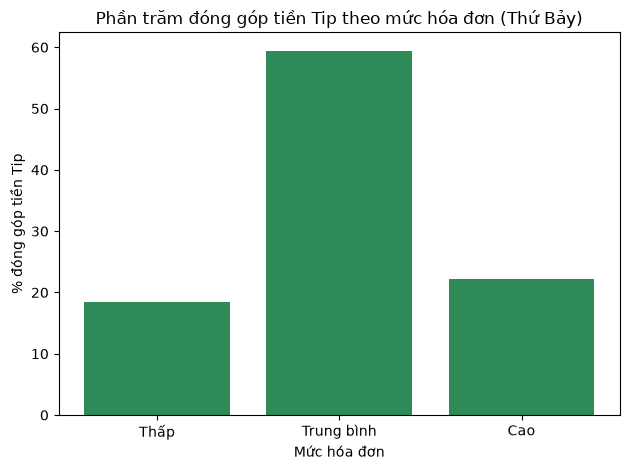

In [5]:
plt.bar(ket_qua.index, ket_qua['Percent_Contribution'], color='seagreen')
plt.title('Phần trăm đóng góp tiền Tip theo mức hóa đơn (Thứ Bảy)')
plt.xlabel('Mức hóa đơn')
plt.ylabel('% đóng góp tiền Tip')
plt.tight_layout()
plt.show()